# risk_gru 02 — Training, evaluation, honesty
Criteria were written in `FICHE.md` **before** running. This notebook runs a reduced version (60 seasons, 2 seeds) so it executes in minutes;
the full figures (200 seasons, 5 seeds) are in `docs/research/gateway-risk-gru.md`.

**Model.** A 1-layer GRU (hidden 16, ≈1.5 k parameters) reading 14 daily vectors of 12 features, then a linear head giving 3 logits (day +1, +2, +3).
Loss: binary cross-entropy with half-strength positive weighting (fires are rare). Early stopping on validation average precision.
**Why a GRU and not an LSTM.** Fewer parameters, same job for 14 steps, and the numpy re-implementation on the gateway is shorter (3 gates instead of 4).

In [1]:
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().resolve().parents[1]
sys.path[:0] = [str(ROOT / "python/src"), str(ROOT.parent / "common/python/src"), str(ROOT.parents[1] / "box/fwi/python/src")]
from risk_gru import experiments as E, predictor
from gw_common import reliability, ece

## 1. S1 — memory is additive
Baselines: *persistence* (is there a fire today?), *fwi_threshold* (the operational rule), logistic regression on today's values (*lr_cur*) and on the whole window (*lr_win*),
gradient boosting (*gbm*), and the *oracle* (the true probability, unreachable in practice).

In [2]:
r1 = E.run_synthetic(60, seed=0, gru_seeds=2, epochs=40)
Xte, Yte, mte = r1["data"][2]
def show(rows, h=1):
    print(f"{'model':14s} {'AUROC':>6s} {'AP':>6s}  AP 95% block-bootstrap CI")
    for n, hh, a, alo, ahi, p, plo, phi, b in rows:
        if hh == h: print(f"{n:14s} {a:6.3f} {p:6.3f}  [{plo:.3f}, {phi:.3f}]")
show(E.table(r1["scores"], Yte, mte["block"]))

model           AUROC     AP  AP 95% block-bootstrap CI
persistence     0.548  0.085  [0.060, 0.122]
fwi_threshold   0.767  0.180  [0.140, 0.235]
lr_cur          0.790  0.195  [0.147, 0.272]
lr_win          0.802  0.211  [0.159, 0.281]
gbm             0.799  0.199  [0.149, 0.255]
gru             0.817  0.215  [0.161, 0.285]
oracle          0.826  0.259  [0.189, 0.343]


**Reading.** If the GRU is not clearly above `lr_cur` here, the recurrence adds nothing when the memory is additive: the engineered FWI codes already summarise the past.

## 2. S2 — non-additive memory
Same weather; the hazard now contains (length of the current heat wave) × (wind)². This is the case a recurrent network is *supposed* to help.

In [3]:
r2 = E.run_synthetic(60, seed=0, gru_seeds=2, epochs=40, variant="interaction")
show(E.table(r2["scores"], r2["data"][2][1], r2["data"][2][2]["block"]))

model           AUROC     AP  AP 95% block-bootstrap CI
persistence     0.631  0.162  [0.097, 0.231]
fwi_threshold   0.793  0.200  [0.144, 0.277]
lr_cur          0.823  0.278  [0.192, 0.379]
lr_win          0.842  0.275  [0.195, 0.372]
gbm             0.837  0.296  [0.218, 0.393]
gru             0.842  0.356  [0.255, 0.458]
oracle          0.892  0.581  [0.472, 0.667]


## 3. Real data — Algerian, leave-one-site-out (evidence level A)
Train on one site, test on the other. About 85–89 windows per test site: **wide intervals, no strong claim possible**.

In [4]:
alg = ROOT.parents[1] / "data/algerian/Algerian_forest_fires_dataset_UPDATE.csv"
ra = E.run_algerian(alg, gru_seeds=2, epochs=40)
for site, v in ra.items():
    print("\n== test site:", site, "| windows:", len(v["Y"]), "| positives h=1:", int(v["Y"][:, 0].sum()))
    show(E.table(v["scores"], v["Y"], v["meta"]["block"]))


== test site: Bejaia | windows: 89 | positives h=1: 46


model           AUROC     AP  AP 95% block-bootstrap CI
persistence     0.775  0.741  [0.560, 0.902]
fwi_threshold   0.833  0.791  [0.641, 0.914]
lr_cur          0.767  0.779  [0.575, 0.913]
lr_win          0.659  0.650  [0.418, 0.878]
gbm             0.586  0.588  [0.379, 0.806]
gru             0.690  0.661  [0.475, 0.838]

== test site: SidiBelAbbes | windows: 85 | positives h=1: 63


model           AUROC     AP  AP 95% block-bootstrap CI
persistence     0.671  0.879  [0.726, 0.944]
fwi_threshold   0.736  0.866  [0.770, 0.942]
lr_cur          0.640  0.777  [0.625, 0.928]
lr_win          0.517  0.753  [0.585, 0.935]
gbm             0.646  0.813  [0.676, 0.944]
gru             0.649  0.795  [0.665, 0.915]


## 4. Calibration (synthetic S1)
A probability that is not calibrated cannot be thresholded sensibly. We fit a Platt scaling on the validation seasons and look at the reliability curve on the test seasons.

ECE (day +1): 0.0162 | bin counts: [2396, 224, 78, 16, 1]


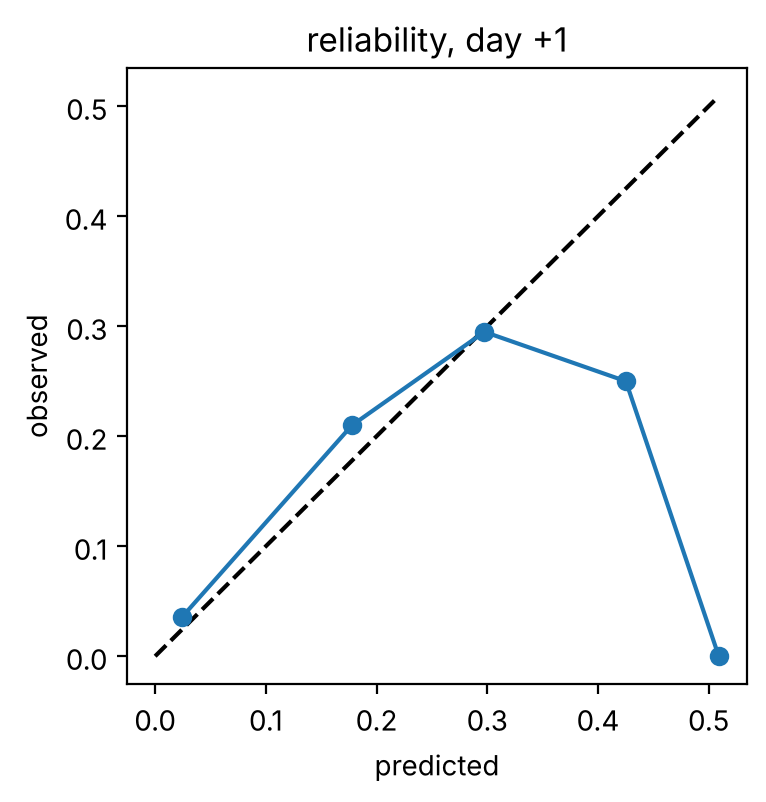

In [5]:
from risk_gru.train import calibrated
p = calibrated(r1["model"], r1["calib"], Xte)[:, 0]
rel = reliability(Yte[:, 0], p, bins=8)
cx, cy = [r[0] for r in rel], [r[1] for r in rel]
print("ECE (day +1):", round(ece(p, Yte[:, 0]), 4), "| bin counts:", [r[2] for r in rel])
plt.figure(figsize=(4, 4)); plt.plot([0, max(cx)], [0, max(cx)], "k--"); plt.plot(cx, cy, "o-"); plt.xlabel("predicted"); plt.ylabel("observed"); plt.title("reliability, day +1"); plt.show()

## 5. Cost on the gateway
The runtime class uses numpy only. One update = one day for one box.

In [6]:
MODEL = ROOT / "models/risk_gru_demo_synthetic.npz"
pr = predictor.RiskPredictor(MODEL)
day = dict(temp=34, rh=28, wind=18, rain=0.0, ffmc=92, dmc=90, dc=400, isi=12, bui=100, fwi=30, month=7)
for _ in range(14): pr.update(day)
t0 = time.perf_counter()
for _ in range(2000): out = pr.update(day)
print(out, "\nmean time per update: %.3f ms (this cloud CPU; not measured on the VIM4)" % ((time.perf_counter() - t0) / 2000 * 1e3))
print("model file bytes:", MODEL.stat().st_size)

{'p_day1': 0.3115900832668039, 'p_day2': 0.2893747765915612, 'p_day3': 0.2794280247483276, 'level': 'high', 'provisional': False, 'missing_days': 0, 'model': 'DEMO trained on synthetic seasons (200, seed 0). Never saw a real fire. Not for field use.'} 
mean time per update: 0.200 ms (this cloud CPU; not measured on the VIM4)
model file bytes: 16300


## 6. Conclusions to carry forward (see research log for full numbers)
- The pipeline is correct (oracle gap measured, parity with numpy tested, no leakage by construction).
- On additive synthetic memory the GRU matches simple models; the oracle gap is mostly irreducible noise.
- On real Algerian data, the plain FWI threshold is the best single scorer; learned models do not beat it with 85 test windows.
- Therefore: **the GRU is a research/demonstration block, not a proven improvement.** The only claim we may make is that it runs on the gateway in well under a millisecond and that we know how to evaluate it honestly.